In [1]:
import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn import svm
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import Lasso, LogisticRegression, RidgeClassifier
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    auc,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.utils import shuffle as sk_shuffle
from toolbox import (
    Masking,
    combined_frequency_roc_analysis,
    compute_ROC_patient_split,
    find_all_indices,
    get_freqs,
    hot_coding,
    visualize_Category_hist,
)
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient, color_palette_full

In [2]:
# load masking
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)
# set prints off
mask.prints = False

## Contents

- Data loading
- Train and test split
- Data augmentation for train data
- Masking and IIVV selection
- Implementation of classification models
- Performance documentation
    - Dataframe
    - TP, TN, FN, FP rates
    - Confusion matrix
    - Sensitivity $S_{sens}$
    - Specificity $S_{spec}$
    - "Yudens’ rule" $J$ / Accuracy $\rightarrow$ f1 score

Furthermore:

- colormaps for SVM, RF, CNN

### Data loading

In [3]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    Avg_Cutpats,
    LesionAssessment,
    labels_healthy_vs_cancer,
    labels_cancer_vs_hbd,
    labels_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 244 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 229 

	Info:	z-score Zdata
before: 434.20845093924504 699.3585400487347
Normalized along the frequency axis.

after: -4.3347838749237164e-17 1.000000000000001

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 229 


**Select classification basis task `class_task`**

- `"healthy_vs_cancer"`
- `"cancer_vs_hbd"`
- `"MC"`

In [4]:
class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

Healthy vs. cancer

Healthy: 89 entries
Cancer: 91 entries


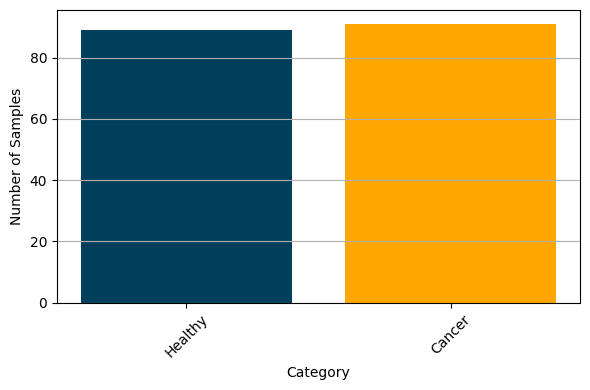

Available cases: ['Cancer' 'Healthy']
Coding: -> forward
{np.str_('Cancer'): [1, 0], np.str_('Healthy'): [0, 1]}

Inverse mapping: {(1, 0): 'Cancer', (0, 1): 'Healthy'}
(180, 31, 7728) (180, 2) (180,)


In [5]:
if class_task == "healthy_vs_cancer":
    print("Healthy vs. cancer\n")
    select_idx = find_all_indices(
        labels_healthy_vs_cancer, ["Healthy", "Cancer"], split=False
    )
    labels = labels_healthy_vs_cancer[select_idx]
    target_num_augmentation = 150


elif class_task == "cancer_vs_hbd":
    print("\nHealthy vs. HDB\n")
    select_idx = find_all_indices(
        labels_cancer_vs_hbd, ["Non-cancer", "Cancer"], split=False
    )
    labels = labels_cancer_vs_hbd[select_idx]
    target_num_augmentation = 150

elif class_task == "MC":
    print("\nMC\n")
    select_idx = find_all_indices(
        labels_MC,
        ["Healthy", "Cancer", "Mild dysplasia", "Severe dysplasia", "Benign"],
        split=False,
    )
    labels = labels_MC[select_idx]
    target_num_augmentation = 100

visualize_Category_hist(labels)
Case = patient_no[select_idx]
X = Zdata[select_idx, ...]
Y, inverse_mapping = hot_coding(labels)
print("\nInverse mapping:", inverse_mapping)
print(X.shape, Y.shape, Case.shape)

### Train and test split

In [6]:
random_state = 0
n_folds = 5


def generate_folds(Case, n_folds, random_state):
    unique_patients = np.unique(Case)
    np.random.seed(random_state)

    # Check if Y is in one-hot encoding
    if len(Y.shape) == 1 or Y.shape[1] == 1:
        raise ValueError("Labels (Y) must be in one-hot encoding format")
    # Custom splitting to ensure 70/30 ratio
    patient_indices = np.arange(len(unique_patients))
    np.random.shuffle(patient_indices)

    # Split these indices into n_folds
    fold_size = len(patient_indices) // n_folds
    folds = []

    for i in range(n_folds):
        if i == n_folds - 1:
            # Last fold gets all remaining patients
            test_indices = patient_indices[i * fold_size :]
        else:
            test_indices = patient_indices[i * fold_size : (i + 1) * fold_size]
        # Training indices are all other indices
        train_indices = np.setdiff1d(patient_indices, test_indices)
        folds.append((train_indices, test_indices))

    return folds


folds = generate_folds(Case, n_folds, random_state)

### Data augmentation for train data

- If you want you can set the SNR in dB here using the variable `snr_db`

In [7]:
snr_db = 30  # dB


def add_noise_2d(signal, snr_db):
    signal_power = np.nanmean(signal**2)
    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear
    noise = np.sqrt(noise_power) * np.random.normal(size=signal.shape)
    return signal + noise


def select_cat_data(X, Y, select: int):
    """
    Get all indices of a single category
    """
    matches = np.all(Y == select, axis=1)
    idxs = np.where(matches)[0]

    return X[idxs, ...], idxs


def data_augmentation(X, Y, tar_num, snr_db, shuffle_data=True, random_state=42):
    if len(Y.shape) == 2:
        cats = np.unique(Y, axis=0)
    else:
        cats = np.unique(Y)
    X_aug = list()
    Y_aug = list()

    for selected_cat in cats:
        # print("Cat:", selected_cat)
        X_select, idxs = select_cat_data(X, Y, selected_cat)
        aug_num = tar_num - len(idxs)
        aug_idxs = np.random.randint(0, len(idxs), size=aug_num)

        print(f"There are {len(idxs)} available samples, {aug_num} will be created.")

        for Xs in X_select:
            X_aug.append(Xs)
            Y_aug.append(selected_cat)

        # augmentation:
        for aug_idx in aug_idxs:
            Xs_noisy = add_noise_2d(X_select[aug_idx], snr_db)
            X_aug.append(Xs_noisy)
            Y_aug.append(selected_cat)
    X_aug = np.array(X_aug)
    Y_aug = np.array(Y_aug)
    if shuffle_data:
        X_aug, Y_aug = sk_shuffle(X_aug, Y_aug, random_state=random_state)

    return X_aug, Y_aug

**The data augmentation is implemented here and will be called during the 5-fold cross validation!**

### Masking and IIVV selection

In [8]:
# load frequency selection
tmp = np.load("results/freq_fold_results.npz", allow_pickle=True)
top_freqs_baseline = tmp["top_freqs_baseline"]

Freq_sel = {
    "Top 2": top_freqs_baseline[:2],
    "Top 3": top_freqs_baseline[:3],
    "Top 5": top_freqs_baseline[:5],
    "Top 12": top_freqs_baseline[:12],
    "All": top_freqs_baseline,  # np.arange(31), # it doesn't matter
}

# load masking selection
Mask_sel = {
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Close skip 1": "vv_distance_close_skip_1",
    "All": "all",
}

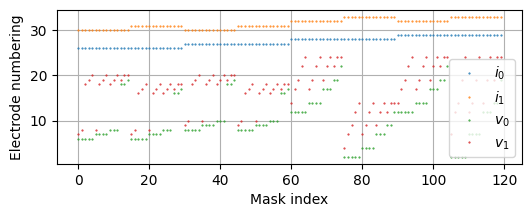

In [9]:
Fsel = "Top 3"
Msel = "Med. a+ ext."


mask.IIVV_mask(Mask_sel[Msel])

### Implementation of classification models

In [10]:
def Model(
    architecture: str,
    X_train,
    Y_train,
    X_test,
    Y_test,
    random_state,
    inverse_mapping,
    fold,
    Msel,
    Fsel,
    class_task,
):
    """
    Train and evaluate a classifier based on the specified architecture.

    Parameters
    ----------
    architecture : str
        Specifies the classifier to use. Supported options are:
            # - "SVMscaler" : Supported Vector Machine with StandardScaler and OneVsRest strategy.
            - "SVM"       : Supported Vector Machine with OneVsRest strategy (no scaler).
            - "RF"        : Random Forest classifier with optional StandardScaler.
            # - "LR"        : Logistic Regression with StandardScaler and OneVsRest strategy.
            # - "RidgeRegr" : Ridge Classifier with StandardScaler and OneVsRest strategy.
            - "Lasso"     : Lasso-like classifier using Logistic Regression with L1 penalty.

    """
    if architecture == "SVMscaler":
        print("\nNew Supported vector machine (SVM) with StandardScaler\n")
        m = make_pipeline(
            StandardScaler(),
            OneVsRestClassifier(
                SVC(kernel="linear", probability=True, random_state=random_state)
            ),
        )
    elif architecture == "SVM":
        print("\nSupported vector machine (SVM)\n")
        m = OneVsRestClassifier(
            SVC(kernel="linear", probability=True, random_state=random_state)
        )

    elif architecture == "RF":
        print("\nRandom Forest (RF)\n")
        m = make_pipeline(
            StandardScaler(),
            OneVsRestClassifier(
                RandomForestClassifier(max_depth=5, random_state=random_state)
            ),
        )

    elif architecture == "LR":
        print("\nLogistic Regression (LR)\n")
        m = make_pipeline(
            StandardScaler(),
            OneVsRestClassifier(
                LogisticRegression(max_iter=1000, random_state=random_state)
            ),
        )

    # elif architecture == "RidgeRegr":
    #    print("\nRidge Classifier (RidgeRegr)\n")
    #    m = make_pipeline(
    #        StandardScaler(),
    #        OneVsRestClassifier(RidgeClassifier(random_state=random_state)),
    #    )

    elif architecture == "Lasso":
        print("\nLasso Classifier (Lasso)\n")
        m = make_pipeline(
            StandardScaler(),
            OneVsRestClassifier(
                LogisticRegression(
                    penalty="l1",
                    solver="saga",
                    max_iter=2000,
                    random_state=random_state,
                )
            ),
        )

    else:
        raise ValueError(f"Unknown architecture: {architecture}")

    # Fit and predict
    y_score = m.fit(X_train, Y_train).predict_proba(X_test)
    Y_pred = m.predict(X_test)

    if Y_train.shape[1] == 2:
        y_test_tuples = [tuple(row) for row in Y_test.astype(int)]
        y_pred_tuples = [tuple(row) for row in Y_pred.astype(int)]
        # inverse mapping
        y_test_labels = [inverse_mapping[t] for t in y_test_tuples]
        y_pred_labels = [inverse_mapping[t] for t in y_pred_tuples]
        class_labels = list(inverse_mapping.values())
        # confusion matrix
        cm = confusion_matrix(y_test_labels, y_pred_labels, labels=class_labels)

        TP = cm[0, 0]  # true positives (TP)
        TN = cm[1, 1]  # true negatives (TN)
        FN = cm[0, 1]  # false negatives (FN)
        FP = cm[1, 0]  # false positives (FP)

        # print("Manual acc=", (TP + TN) / (TP + TN + FP + FN))

        class_labels = list(inverse_mapping.values())
        # fig, ax = plt.subplots(figsize=(6, 6))
        # disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_labels)
        # disp.plot(
        #    cmap=cmap_gradient, ax=ax
        # )  # ax übergeben, sonst überschreibt plot() die Größe
        # plt.title("Confusion Matrix")
        # plt.show()

    score = roc_auc_score(Y_test, y_score)
    recall = recall_score(Y_test, Y_pred, labels=None, average="weighted")
    f1 = f1_score(Y_test, Y_pred, average="weighted")

    print("ROC AUC :", score)
    print("Recall  :", recall)
    print("F1 score:", f1)

    performance = {
        "Architecture": architecture,
        "Fold": fold,
        "Random_state": random_state,
        "ROC AUC": score,
        "Recall": recall,
        "F1-score": f1,
        "Mask": Msel,
        "Freq. selection": Fsel,
        "Task": class_task,
    }
    return performance

In [ ]:
stats_df = []
use_models = ["SVM", "RF", "Lasso"]
output_prints = False

for random_state in range(50):
    print("random_state", random_state)
    folds = generate_folds(Case, n_folds, random_state)
    for fold_idx, (train_patients_idx, test_patients_idx) in enumerate(folds):
        fold = fold_idx + 1

        # Get patient IDs for training and testing
        unique_patients = np.unique(Case)
        train_patients = unique_patients[train_patients_idx]
        test_patients = unique_patients[test_patients_idx]
        if output_prints:
            print("Train patients:", train_patients)
            print("Test patients:", test_patients)
        # Create masks for training and testing samples
        train_mask = np.isin(Case, train_patients)
        test_mask = np.isin(Case, test_patients)
        # Verify split is close to 70/30
        train_pct = train_mask.mean() * 100
        test_pct = test_mask.mean() * 100
        # print(f"Fold {fold}: {train_pct:.1f}% train / {test_pct:.1f}% test")

        # Count samples and patients in each set
        train_samples = np.sum(train_mask)
        test_samples = np.sum(test_mask)
        train_patient_count = len(train_patients)
        test_patient_count = len(test_patients)

        if output_prints:
            print(f"Fold {fold}: {train_pct:.1f}% train / {test_pct:.1f}% test")
            print(
                f"  Training: {train_samples} samples from {train_patient_count} patients"
            )
            print(
                f"  Testing:  {test_samples} samples from {test_patient_count} patients"
            )

        # Get training and testing data
        X_train, Y_train = data_augmentation(
            X[train_mask],
            Y[train_mask],
            target_num_augmentation,
            snr_db,
            shuffle_data=True,
            random_state=random_state,
        )

        # unaugmented test data:
        X_test = X[test_mask]
        Y_test = Y[test_mask]

        # here the frequency and IIVV selection is done
        X_train = X_train[:, Freq_sel[Fsel], :]
        X_test = X_test[:, Freq_sel[Fsel], :]
        # IIVV selection
        X_train = X_train[:, :, mask.mask]
        X_test = X_test[:, :, mask.mask]
        # Reshape
        X_train = X_train.reshape(X_train.shape[0], -1)
        X_test = X_test.reshape(X_test.shape[0], -1)

        # ------ Models ------
        for use_model in use_models:
            try:
                pf = Model(
                    use_model,
                    X_train,
                    Y_train,
                    X_test,
                    Y_test,
                    random_state,
                    inverse_mapping,
                    fold,
                    Msel,
                    Fsel,
                    class_task,
                )
                stats_df.append(pf)
            except:
                print("random state:", random_state, "for", use_model, "isn't working.")
        # -----------------

df = pd.DataFrame(stats_df)
df.to_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}.csv", index=False)

In [ ]:
df = pd.read_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}.csv")

In [ ]:
# results for 50 random states
plt.figure(figsize=(6, 3))
sns.boxplot(
    data=df,
    x="Fold",
    y="Score",
    hue="Architecture",
    palette="deep",  # colorblind
)

plt.ylabel("AUC")
plt.xlabel("Folds")
plt.legend(title="Architecture")
plt.grid(True)
plt.tight_layout()
# plt.savefig("results/boxplot_architecture", bbox_inches="tight")
plt.show()

In [ ]:
for use_model in use_models:
    print(
        f"Mean score {use_model}",
        np.round(df.loc[df["Architecture"] == use_model, "Score"].mean(), 3),
    )
    print(
        f"Max score {use_model}",
        np.round(df.loc[df["Architecture"] == use_model, "Score"].max(), 3),
    )
    print(
        f"Min score {use_model}",
        np.round(df.loc[df["Architecture"] == use_model, "Score"].min(), 3),
    )

**Colomns for final Evaluation**

- Fsel (Frequency selection)
- Msel (IIVV masking selection)
- ClassTask (Classification task)
- Architecture
- Fold
- random_state
- Score
- F1
- Sensitivity
- Specitivity